In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
import sys
sys.path.append('..')

import numpy as np
import matplotlib.pyplot as plt

# from preprocessing.generate_word_frequency import MEDIAN_ZIPF_FREQUENCY

from meg import Meg

meg = Meg('sub-31_ses-01_task-listen_run-01', filter=True, maxwell=True)

/home/felipe/git/phd/meg/nbs/../meg.py:11: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  import pandas as pd


Loaded bad-channel lists from /mnt/sda/data-output/phd/Pallier2025_results/preprocessing/sub-31/sub-31_ses-01_task-listen_run-01/meg/bad_channels.json.
Maxwell filtering started at 2026-10-18 14:21:04.
Maxwell filtering ended at 2026-10-18 14:21:15; elapsed 10.64 seconds.
Filtering gradiometer data (0.5–20 Hz) started at 2026-10-18 14:21:15.
Filtering ended at 2026-10-18 14:21:19; elapsed 4.33 seconds.


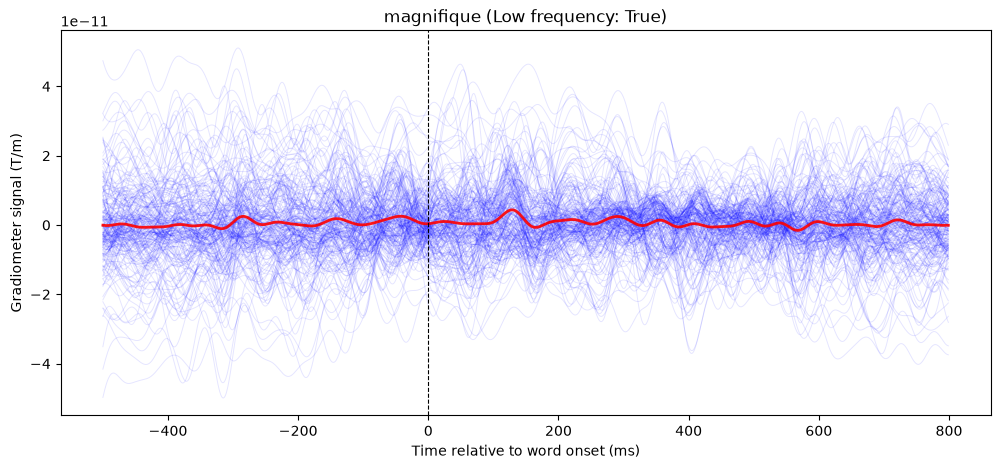

In [15]:
word_idx = 11
before_ms, after_ms = -500, 800

data = meg.get_grad_by_word(word_idx, before_ms, after_ms)
times_ms = before_ms + np.arange(data.shape[1]) * 1000 / meg.sfreq

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(times_ms, data.T, color='blue', alpha=0.1, linewidth=0.7)
ax.plot(times_ms, data.mean(axis=0), color='red', alpha=0.9, linewidth=2)
ax.axvline(0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer signal (T/m)')
ax.set_title(f"{meg.events.loc[word_idx, 'stimulus']} (Low frequency: {meg.events.loc[word_idx, 'low_frequency']})")
plt.show()